# PneuNet E7-T — Hasil eksperimen

Notebook ini menampilkan hasil training, evaluasi, dan pengukuran latency yang sudah tersimpan. Letakkan folder `outputs/` di sebelah notebook, lalu pilih **Run All** untuk membaca ulang artefaknya. Tabel dan gambar yang tertanam juga bisa langsung dilihat saat notebook dibuka.

Atur `RESULTS_DIR` pada cell pertama untuk menampilkan hasil run lain, misalnya `Path("runs/seed42/outputs")`.

In [1]:
import csv
import json
from html import escape
from pathlib import Path

from IPython.display import HTML, Image, display

RESULTS_DIR = Path("outputs")
OUTPUTS = next((root / RESULTS_DIR
                for base in (Path.cwd(), *Path.cwd().parents)
                for root in (base, base / "PneuNet_E7_T_Repo")
                if (root / RESULTS_DIR / "selection.json").is_file()), None)
if OUTPUTS is None:
    raise FileNotFoundError(f"Direktori hasil {RESULTS_DIR} belum tersedia atau ekspornya belum selesai.")

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_csv(path):
    with path.open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

def show_table(headers, rows):
    head = "".join(f"<th>{escape(str(header))}</th>" for header in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
                   for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

## Ringkasan training

Kandidat,Seed,Parameter,Epoch selesai,Epoch terpilih,Macro-F1 validation,Macro-F1 test,AUROC test
E7-T,42,"229,544",15,6,91.1747%,95.0635%,0.987552


Hasil arsip bersifat eksploratif karena test digunakan dalam pemilihan kandidat.


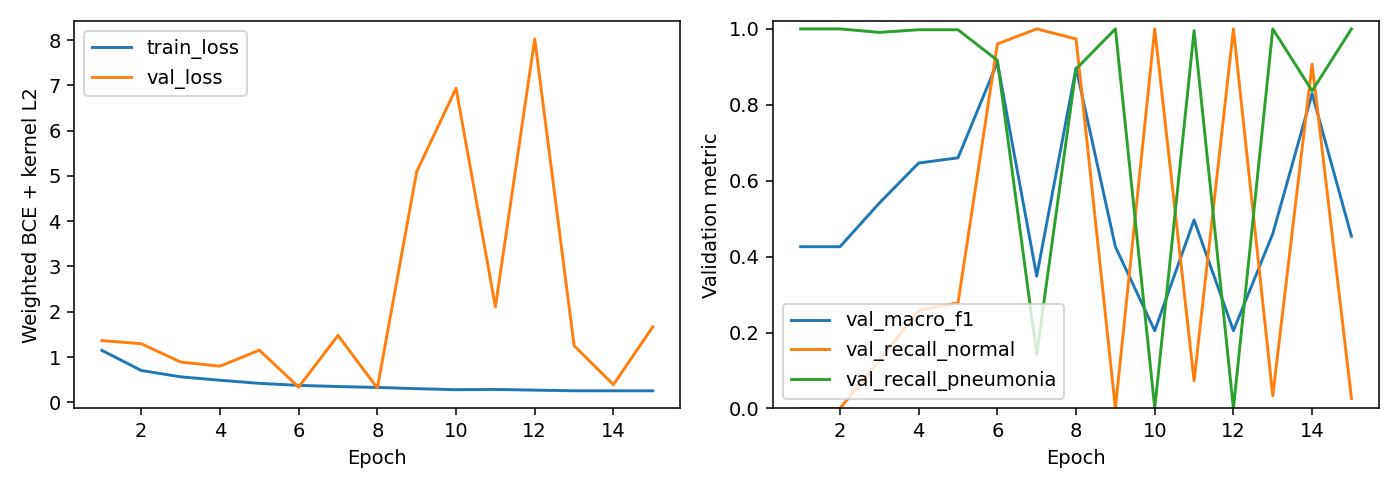

In [2]:
selection = read_json(OUTPUTS / "selection.json")
history_file = OUTPUTS / "history.csv"
history = read_csv(history_file) if history_file.is_file() else []
total_epochs = history[-1]["epoch"] if history else selection.get("epochs_completed") or "N/A"
test = read_json(OUTPUTS / "test_metrics.json")
show_table(
    ("Kandidat", "Seed", "Parameter", "Epoch selesai", "Epoch terpilih",
     "Macro-F1 validation", "Macro-F1 test", "AUROC test"),
    [(f"E7-{selection['candidate']}", selection["seed"], f"{selection['parameters']:,}",
      total_epochs, selection["best_epoch"], f"{selection['validation_macro_f1']:.4%}",
      f"{test['macro_f1']:.4%}", f"{test['roc_auc']:.6f}")],
)
if selection.get("test_used_for_selection"):
    print("Hasil arsip bersifat eksploratif karena test digunakan dalam pemilihan kandidat.")
if (OUTPUTS / "learning_curve.png").is_file():
    display(Image(filename=str(OUTPUTS / "learning_curve.png")))

## Evaluasi train, validation, dan test

Macro-F1,Accuracy,AUROC,PR-AUC,FP NORMAL,FN PNEUMONIA
90.8679%,92.4882%,0.985255,0.994978,28,321


Kelas,Precision,Recall,F1,Jumlah citra
NORMAL,78.4708%,97.6628%,87.0212%,1198
PNEUMONIA,99.1125%,90.6903%,94.7145%,3448


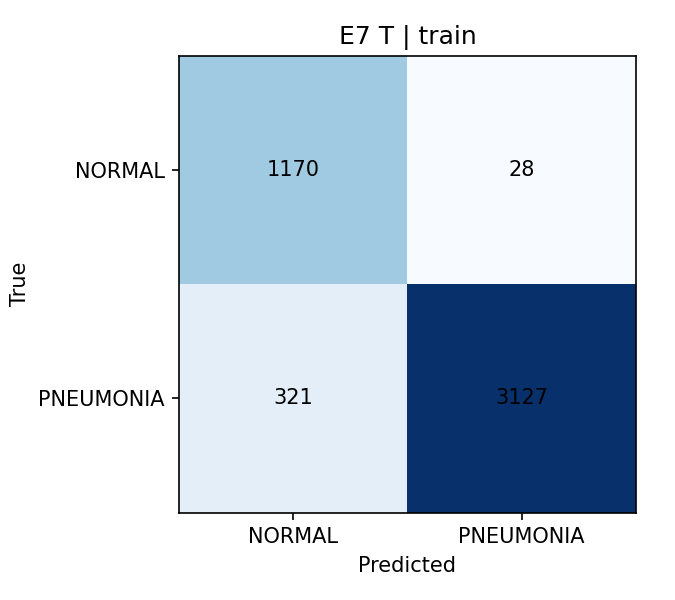

Macro-F1,Accuracy,AUROC,PR-AUC,FP NORMAL,FN PNEUMONIA
91.1747%,92.8328%,0.984030,0.994738,6,36


Kelas,Precision,Recall,F1,Jumlah citra
NORMAL,80.1105%,96.0265%,87.3494%,151
PNEUMONIA,98.5185%,91.7241%,95.0000%,435


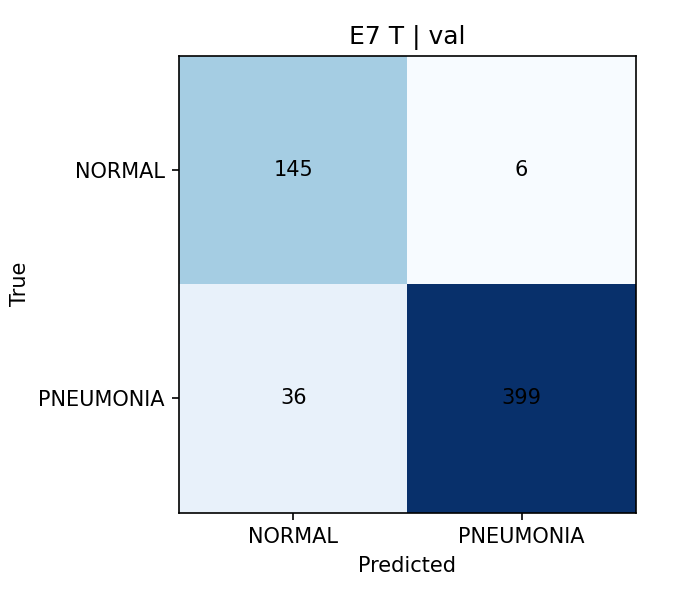

Macro-F1,Accuracy,AUROC,PR-AUC,FP NORMAL,FN PNEUMONIA
95.0635%,95.3526%,0.987552,0.991859,12,17


Kelas,Precision,Recall,F1,Jumlah citra
NORMAL,92.8870%,94.8718%,93.8689%,234
PNEUMONIA,96.8831%,95.6410%,96.2581%,390


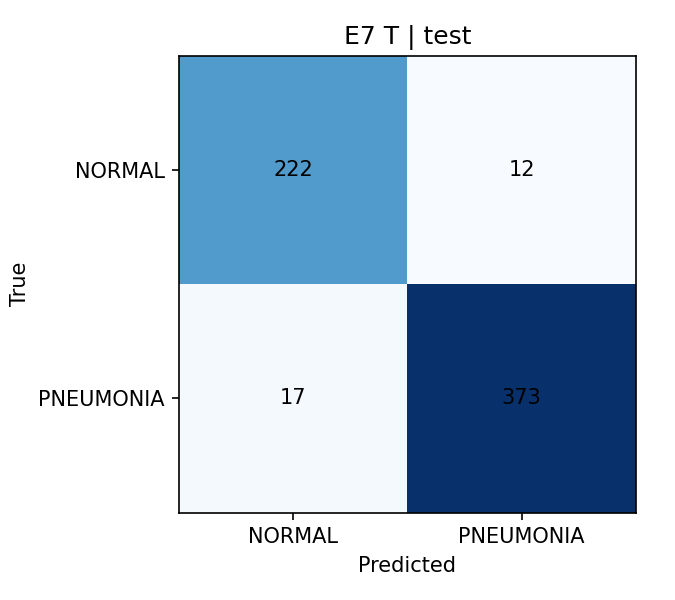

In [3]:
for split, label in (("train", "Train"), ("val", "Validation"), ("test", "Test")):
    metrics = read_json(OUTPUTS / f"{split}_metrics.json")
    report = read_json(OUTPUTS / f"{split}_report.json")
    display(HTML(f"<h3>{label}</h3>"))
    show_table(
        ("Macro-F1", "Accuracy", "AUROC", "PR-AUC", "FP NORMAL", "FN PNEUMONIA"),
        [(f"{metrics['macro_f1']:.4%}", f"{metrics['accuracy']:.4%}",
          f"{metrics['roc_auc']:.6f}", f"{metrics['pr_auc']:.6f}",
          metrics["fp_normal"], metrics["fn_pneumonia"])],
    )
    show_table(
        ("Kelas", "Precision", "Recall", "F1", "Jumlah citra"),
        ((name, f"{report[name]['precision']:.4%}", f"{report[name]['recall']:.4%}",
          f"{report[name]['f1-score']:.4%}", int(report[name]["support"]))
         for name in ("NORMAL", "PNEUMONIA")),
    )
    display(Image(filename=str(OUTPUTS / f"{split}_confusion_matrix.png")))

## Benchmark klasifikasi

Tabel menampilkan T dan baseline P3 yang tersedia. Hasil baseline untuk run baru berasal dari eksperimen arsip.

In [4]:
comparison = read_csv(OUTPUTS / "final_comparison.csv")
show_table(
    ("Model", "Parameter", "Macro-F1 test", "AUROC", "Recall NORMAL",
     "Recall PNEUMONIA", "FP NORMAL", "FN PNEUMONIA", "GFLOPs terhitung"),
    ((row["model"], f"{int(row['parameters']):,}", f"{float(row['macro_f1']):.4%}",
      f"{float(row['roc_auc']):.6f}", f"{float(row['recall_normal']):.4%}",
      f"{float(row['recall_pneumonia']):.4%}", row["fp_normal"], row["fn_pneumonia"],
      f"{float(row['counted_flops']) / 1e9:.2f}" if row["counted_flops"] not in ("", "N/A") else "N/A")
     for row in comparison),
)

Model,Parameter,Macro-F1 test,AUROC,Recall NORMAL,Recall PNEUMONIA,FP NORMAL,FN PNEUMONIA,GFLOPs terhitung
E7 T,"229,544",95.0635%,0.987552,94.8718%,95.6410%,12,17,8.87
PneuNet_E5_P3,"785,192",93.4095%,0.979728,88.4615%,97.1795%,27,11,22.81
DenseNet121_RSNA,"6,948,609",95.0122%,0.983706,92.3077%,97.1795%,18,11,5.51
RAD_DINO,"86,581,249",92.5636%,0.976079,93.5897%,92.5641%,15,29,46.32
DINOv3_ViTL16,"303,130,625",94.7401%,0.986029,95.2991%,94.8718%,11,20,125.68


## Latency inferensi GPU

In [5]:
latency_runs = []
for path in sorted((OUTPUTS / "latency").glob("*/environment.json"), reverse=True):
    environment = read_json(path)
    summary = path.with_name("latency_summary.csv")
    if environment["status"] == "COMPLETE" and summary.is_file():
        latency_runs.append((environment, summary))

if latency_runs:
    environment, summary = next(
        (run for run in latency_runs if not run[0].get("allow_shared_gpu")), latency_runs[0]
    )
    print(environment["gpu"], "|", environment["precision"], "|", environment["started_utc"])
    if environment.get("allow_shared_gpu") and environment.get("gpu_activity_samples", 0):
        print("GPU bersama. Aktivitas proses lain tercatat pada",
              environment["samples_with_other_gpu_activity"], "dari",
              environment["gpu_activity_samples"], "sampel.")
    if environment.get("allow_shared_gpu") and not environment.get("gpu_activity_samples"):
        print("Log aktivitas GPU lain tidak tersedia untuk pengukuran ini.")
    show_table(
        ("Model", "Batch", "Percobaan", "Median ms/batch", "Mean ms/batch", "SD ms/batch",
         "P95 ms/batch", "Median ms/gambar", "Throughput gambar/detik"),
        ((row["model"], row["batch"], row["samples"], f"{float(row['median_ms_batch']):.4f}",
          f"{float(row['mean_ms_batch']):.4f}", f"{float(row['std_ms_batch']):.4f}",
          f"{float(row['p95_ms_batch']):.4f}", f"{float(row['median_ms_image']):.4f}",
          f"{float(row['throughput_images_s']):.2f}") for row in read_csv(summary)),
    )
else:
    print("Belum ada hasil latency lengkap di outputs/latency/.")

NVIDIA A100-SXM4-80GB | FP32 | 2026-11-20T02:39:42.313817+00:00
GPU bersama. Aktivitas proses lain tercatat pada 368 dari 390 sampel.


Model,Batch,Percobaan,Median ms/batch,Mean ms/batch,SD ms/batch,P95 ms/batch,Median ms/gambar,Throughput gambar/detik
E7 T,1,300,11.1089,34.1214,34.5506,89.6013,11.1089,29.31
E7 T,32,300,88.1056,99.1407,41.4778,180.9130,2.7533,322.77
PneuNet_E5_P3,1,300,12.0926,30.6288,31.4353,84.7517,12.0926,32.65
PneuNet_E5_P3,32,300,102.4616,119.3260,46.8684,207.9297,3.2019,268.17
DenseNet121_RSNA,1,300,96.7361,88.0927,27.4700,107.8134,96.7361,11.35
DenseNet121_RSNA,32,300,99.1865,98.2482,25.2238,144.7207,3.0996,325.71
RAD_DINO,1,300,85.6840,72.3063,31.6064,102.9082,85.6840,13.83
RAD_DINO,32,300,154.4160,157.8752,35.8892,223.7278,4.8255,202.69
DINOv3_ViTL16,1,300,181.5752,170.1042,38.0513,216.4800,181.5752,5.88
DINOv3_ViTL16,32,300,441.9583,441.0043,38.4024,500.9493,13.8112,72.56


## Grad-CAM dan atribusi spasial · Target PNEUMONIA

Setiap baris menampilkan satu contoh TP, TN, FP, atau FN berdasarkan prediksi E7-T, dengan PNEUMONIA sebagai kelas positif. Lima kolom model menggunakan citra test P3 yang sama. Judul panel menunjukkan kategori prediksi model tersebut dan probabilitas PNEUMONIA. Ketiga CNN memakai Grad-CAM, sedangkan kedua ViT memakai atribusi spasial gradien × aktivasi. Target PNEUMONIA menggunakan `+logit`.

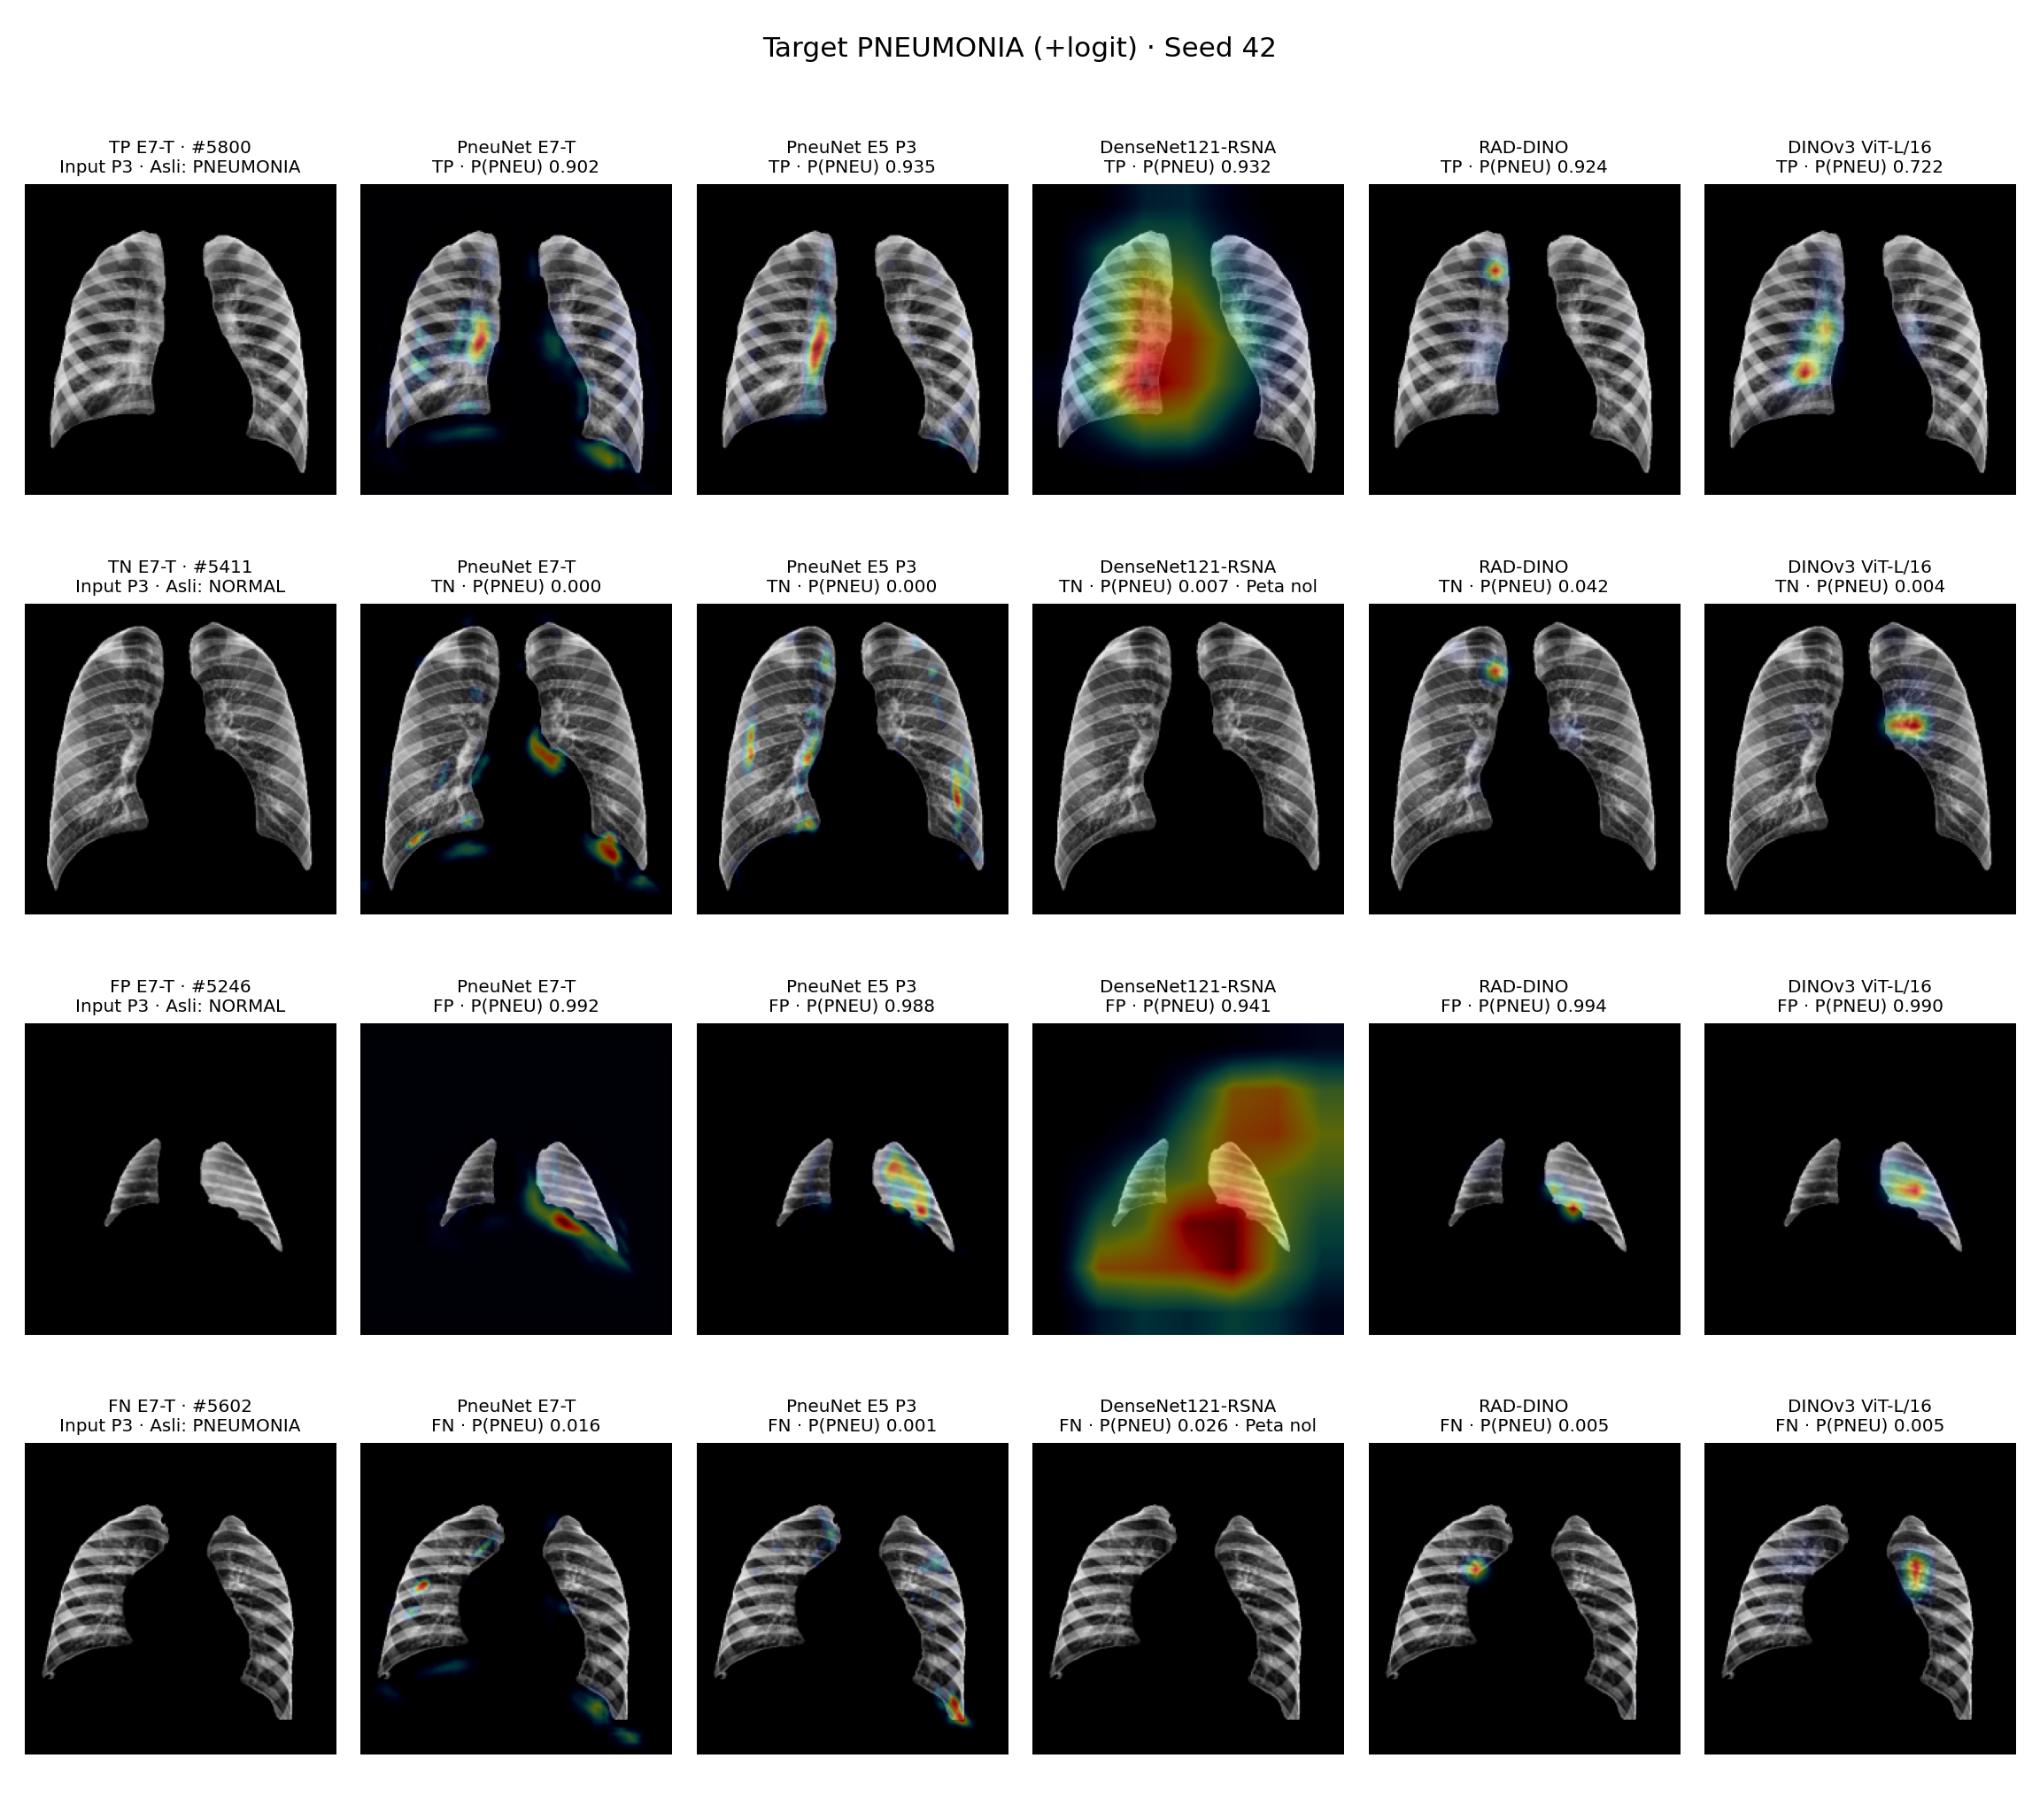

In [6]:
image = OUTPUTS / "attribution_comparison" / "tp_tn_fp_fn_target_1.png"
if image.is_file():
    display(Image(filename=str(image)))
else:
    image = OUTPUTS / "gradcam_e7_t_tp_tn_fp_fn.png"
    if image.is_file():
        display(Image(filename=str(image)))
    else:
        for target, label in ((0, "NORMAL"), (1, "PNEUMONIA")):
            p3 = OUTPUTS / f"gradcam_p3_target_{target}.png"
            if p3.is_file():
                display(HTML(f"<h3>{label} · Grad-CAM pada input P3</h3>"))
                display(Image(filename=str(p3)))
                continue
            for suffix, caption in (("original", "Heatmap asli"), ("lung_mask", "Tampilan dalam mask paru")):
                image = OUTPUTS / f"gradcam_target_{target}_{suffix}.png"
                if image.is_file():
                    display(HTML(f"<h3>{label} · {caption}</h3>"))
                    display(Image(filename=str(image)))